In [13]:
import re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#Loading the data
df = pd.read_excel("Data/Career_Anxiety_due_to_AI.xlsx")
df.head()

,participant_id,university,department,age,gender,academic_year,ai_knowledge,ai_tools_used,career_path,ai_tool_perception,ai_future_perspective,ai_replace_jobs,ai_takeover_time,career_anxiety,consent
0,P0001,Daffodil International University,Department of Computer Science & Engineering,24,Female,4th Year,Medium,"ChatGPT, Quiltbot, Grammarly",Researcher,I don't know for now,"I believe AI will mostly assist humans, with l...",No,Never,Low,Yes
1,P0002,Daffodil International University,Department of Nutrition & Food Engineering,22,Female,2nd Year,Medium,"ChatGPT, Google Gemini, Photomath",Researcher,Google Gemini,I think AI will replace some human jobs but al...,Partially,11–20 years,Medium,Yes
2,P0003,Daffodil International University,Department of Business Administration,22,Female,2nd Year,Low,"ChatGPT, Google Gemini, Microsoft Copilot",Project Manager,Microsoft Copilot,I think AI will replace some human jobs but al...,No,Never,No Anxiety,Yes
3,P0004,Daffodil International University,Department of Nutrition & Food Engineering,21,Female,2nd Year,Low,"ChatGPT, Google Gemini, Don’t know the name",Nutritionist,NaN,I believe AI will significantly replace human ...,Partially,21–50 years,No Anxiety,Yes
4,P0005,Daffodil International University,Department of Nutrition & Food Engineering,21,Male,2nd Year,Medium,"ChatGPT, Google Gemini, Microsoft Copilot",Researcher,ChatGPT,I strongly believe AI cannot take over human a...,No,Never,Low,Yes


In [8]:
# Get the average career anxiety score by academic year
anxiety_order = {
    "No Anxiety": 0,
    "Low": 1,
    "Medium": 2,
    "High": 3
}

df["career_anxiety_score"] = df["career_anxiety"].map(anxiety_order)

avg_career_anxiety = (
    df.groupby("academic_year", observed=True)["career_anxiety_score"]
      .mean()
      .reset_index()
)
avg_career_anxiety.head()

,academic_year,career_anxiety_score
0,1st Year,1.637500
1,2nd Year,1.689340
2,3rd Year,1.706037
3,4th Year,1.733564


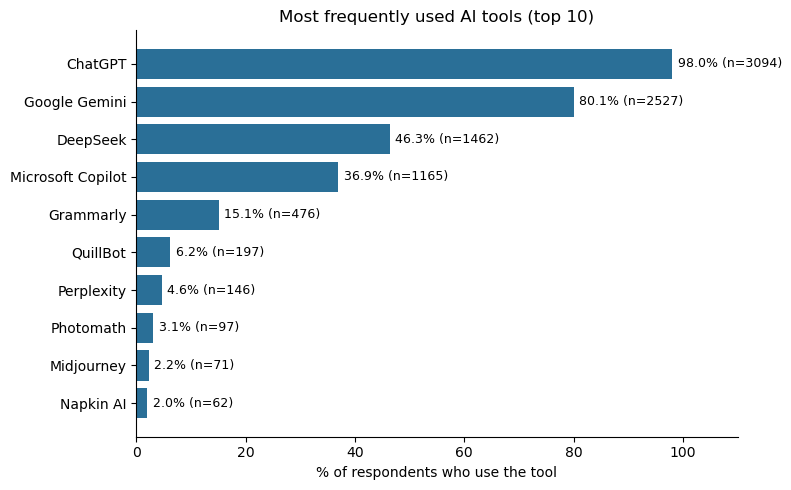

career_anxiety
Medium        1634
Low            648
High           461
No Anxiety     413
Name: count, dtype: int64
Spearman rho (n tools vs anxiety) = 0.024, p = 0.1760


In [9]:
# ---------------------------------------------------------------
# 1. Clean and standardise the free-text tool names
# ---------------------------------------------------------------
CANON = [  # (regex on lowercase text, standard name)
    (r"chatgpt", "ChatGPT"),
    (r"gemini", "Google Gemini"),
    (r"deep\s?seek", "DeepSeek"),
    (r"github copilot", "GitHub Copilot"),
    (r"copilot", "Microsoft Copilot"),
    (r"grammarly", "Grammarly"),
    (r"quil+bot|quiltbot", "QuillBot"),
    (r"perplexity", "Perplexity"),
    (r"photomath", "Photomath"),
    (r"midjourney", "Midjourney"),
    (r"napkin", "Napkin AI"),
    (r"^(grok|gork)|grok", "Grok"),
    (r"claude", "Claude"),
    (r"black\s?box", "Blackbox AI"),
    (r"leonardo", "Leonardo AI"),
    (r"gamma|gama", "Gamma AI"),
    (r"monica", "Monica AI"),
    (r"manus", "Manus AI"),
    (r"humanize", "Humanize AI"),
    (r"^deep ai", "Deep AI"),
]
NOT_A_TOOL = [r"^$", r"don.?t know", r"i dont use", r"^google$", r"google chrome"]

def clean_tool(t):
    t = t.strip().lower()
    if any(re.search(p, t) for p in NOT_A_TOOL):
        return None
    for pat, name in CANON:
        if re.search(pat, t):
            return name
    return t.title()            # keep rare tools as-is (title-cased)

def parse_tools(cell):
    tools = {clean_tool(t) for t in str(cell).split(",")}
    return sorted(t for t in tools if t)

df["tools_list"] = df["ai_tools_used"].apply(parse_tools)

# ---------------------------------------------------------------
# 2. New variables
# ---------------------------------------------------------------
df["n_ai_tools"] = df["tools_list"].str.len()            # count of tools used (numeric)

# one-hot (0/1) columns for each tool used by >= 1% of respondents
exploded = df["tools_list"].explode().dropna()
freq = exploded.value_counts()
common = freq[freq >= 0.01 * len(df)].index
for tool in common:
    col = "uses_" + re.sub(r"\W+", "_", tool.lower()).strip("_")
    df[col] = df["tools_list"].apply(lambda L: int(tool in L))

# ---------------------------------------------------------------
# 3. Plot most frequently used tools
# ---------------------------------------------------------------
top = freq.head(10).sort_values()
pct = top / len(df) * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top.index, pct, color="#2a6f97")
for b, n, p in zip(bars, top.values, pct):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2,
            f"{p:.1f}% (n={n})", va="center", fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("% of respondents who use the tool")
ax.set_title("Most frequently used AI tools (top 10)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 4. Next step: link to career anxiety (ordinal coding)
# ---------------------------------------------------------------
print(df["career_anxiety"].value_counts())
anx_map = {"No Anxiety": 0, "Low": 1, "Medium": 2, "High": 3}   # adjust to your actual labels
df["career_anxiety_num"] = df["career_anxiety"].map(anx_map)

from scipy.stats import spearmanr
r, p = spearmanr(df["n_ai_tools"], df["career_anxiety_num"], nan_policy="omit")
print(f"Spearman rho (n tools vs anxiety) = {r:.3f}, p = {p:.4f}")

career_group
Software & IT Development          932
Research & Academia                778
Data Science & AI                  640
Business, Finance & Management     300
Cybersecurity & Networking         178
Pharmacy, Health & Food Science    165
Engineering (non-software)          92
Creative, Media & Design            45
Public Service                      20
Other                                6
Name: count, dtype: int64

What landed in 'Other':
career_path
Chef    6


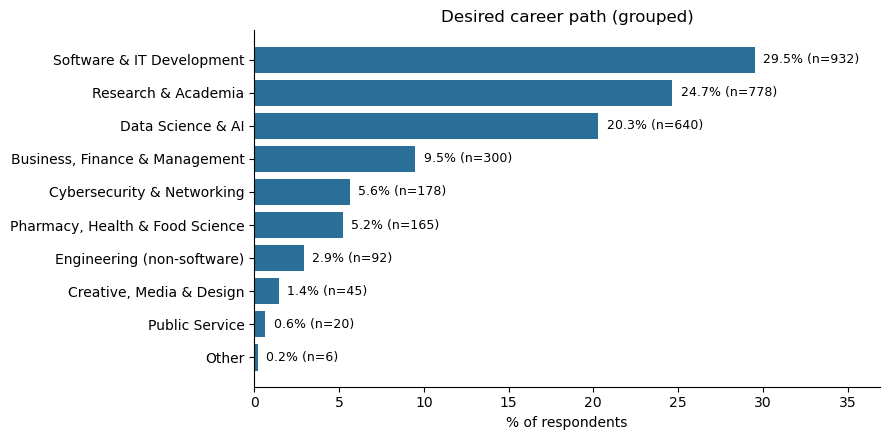

In [10]:
# Keyword rules -> 6 named groups; everything unmatched = "Other"
# If an answer mentions several careers (e.g. "Software Engineer, Researcher"),
# the group whose keyword appears FIRST in the text is used.
# ---------------------------------------------------------------
GROUPS = {
    "Data Science & AI": r"data|dara|\bai\b|ai/ml|\bml\b|machine learning|artificial",
    "Cybersecurity & Networking": r"cyber|cybet|sequrity|security|hacker|network",
    "Software & IT Development": (r"software|develop|devloper|programm|\bapp\b|application|web\b|game|"
                                  r"devops|java|django|laravel|larabel|backend|front-?end|full stack|"
                                  r"sqa|database|blockchain|computer|tech related"),
    "Research & Academia": (r"rese?a?r?ch|reseac|reasea|researc|reseacrher|teacher|lecturer|professor|"
                            r"faculty|scientist|r&d|bioinformatics"),
    "Business, Finance & Management": (r"business|entrepreneur|trader|bank|account|ceo|cfo|corporate|"
                                       r"market|finance|\bhr\b|manager|director|\bmto\b"),
    "Pharmacy, Health & Food Science": r"pharm|nutrition|physician|doctor|medic|food",
    "Engineering (non-software)": (r"engineer|electr|electical|telecom|textile|maint[ae]n[a-z]*nce|"
                                   r"robo|production"),
    "Creative, Media & Design": (r"design|animat|graphic|content creator|journalis|editor|writer|"
                                 r"novelist|news|media|influenc"),
    "Public Service": r"government|civil service|police|army|military|bcs",
}

def group_career(text):
    t = str(text).strip().lower()
    best, best_pos = "Other", 10**9
    for name, pat in GROUPS.items():
        m = re.search(pat, t)
        if m and m.start() < best_pos:
            best, best_pos = name, m.start()
    return best

df["career_group"] = df["career_path"].apply(group_career)

# Check the result
print(df["career_group"].value_counts())
print("\nWhat landed in 'Other':")
print(df.loc[df["career_group"].str.startswith("Other"), "career_path"]
        .str.strip().value_counts().to_string())

# Plot
counts = df["career_group"].value_counts().sort_values()
pct = counts / len(df) * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(counts.index, pct, color="#2a6f97")
for b, n, p in zip(bars, counts.values, pct):
    ax.text(b.get_width() + 0.5, b.get_y() + b.get_height() / 2,
            f"{p:.1f}% (n={n})", va="center", fontsize=9)
ax.set_xlim(0, pct.max() * 1.25)
ax.set_xlabel("% of respondents")
ax.set_title("Desired career path (grouped)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

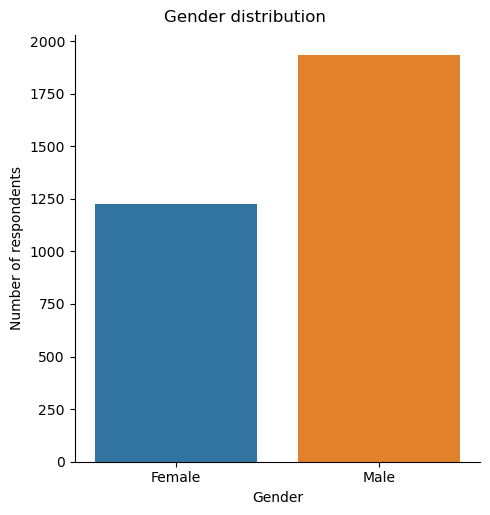

In [11]:
#plot of the gender distribution
g = sns.catplot(data=df, x="gender", hue="gender", kind="count", legend=False)
g.set_axis_labels("Gender", "Number of respondents")
g.figure.suptitle("Gender distribution", y=1.02)
plt.show()


In [17]:
# Is higher AI knowledge associated with more or less career anxiety? 
df['high_anxiety_indicator'] = np.where(df.career_anxiety == "High",
            True, 
            False)


# mean and count of students who have high career anxiety within each combination of ai knowledge category and ai replace jobs category
df.groupby(["ai_knowledge", "ai_replace_jobs"]).agg({"high_anxiety_indicator": ["mean", "count"]})

high_anxiety_indicator      
                                               mean count
ai_knowledge ai_replace_jobs                             
High         Fully                         0.444444    18
             No                            0.142857    35
             Partially                     0.155280   161
Low          Fully                         0.239130    46
             No                            0.117021    94
             Partially                     0.164491   383
Medium       Fully                         0.203620   221
             No                            0.100000   400
             Partially                     0.138049  1753

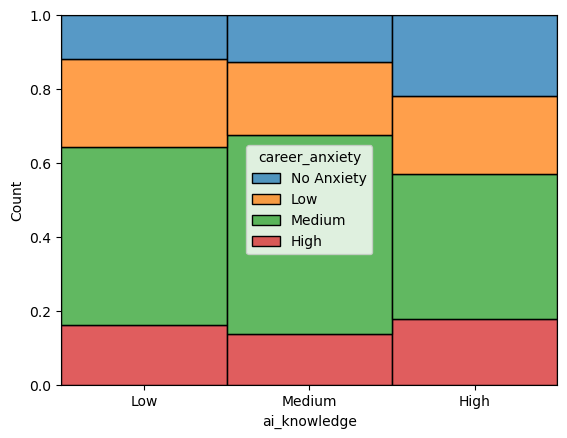

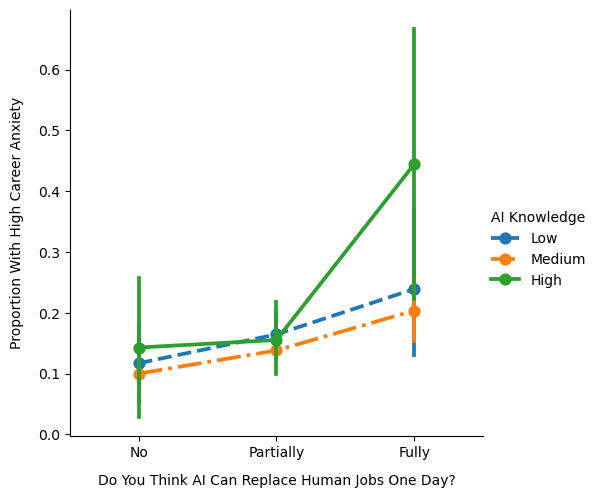

In [54]:
# https://seaborn.pydata.org/tutorial
# Is higher AI knowledge associated with more or less career anxiety? 
df["high_anxiety_indicator"] = np.where(df["career_anxiety"] == "High", 1, 0)

df["ai_knowledge"] = pd.Categorical(df["ai_knowledge"],
                                    categories=["Low", "Medium", "High"],
                                    ordered=True)

sns.histplot(data=df, x="ai_knowledge", hue="career_anxiety", multiple="fill",
            hue_order=["No Anxiety", "Low", "Medium", "High"])

# From this graph, we can notice that the high bar has noticeably larger No Anxiety and High Anxiety sections.
# There is no clear direction they seem to be either or

# Is higher AI knowledge associated with more or less career anxiety? 
g = sns.catplot(
    data=df, x="ai_replace_jobs", y="high_anxiety_indicator", hue="ai_knowledge", kind="point",
    linestyles=["--", "-.", "-"],
    hue_order=["Low", "Medium", "High"]
)
g.set_axis_labels("Do You Think AI Can Replace Human Jobs One Day?", "Proportion With High Career Anxiety", labelpad=10)
g.legend.set_title("AI Knowledge")

# From this graph we can see that the porportion of students with high anxiety shoots up when knowledge is combined with belief (interaction term)
# One critique: The error bar is larger because it is based on a smaller group


In [59]:
classified = pd.read_csv("Data/bangladesh_universities_ai_promotion_classified.csv")
classified

ParserError: Error tokenizing data. C error: Expected 11 fields in line 442, saw 13
